# 02. 업로드 전 메타데이터로 바이럴 여부 예측

- 데이터: 10개국(US, GB, DE, KR, JP, IN, BR, MX, ID, PH) 인기 급상승 영상 국가별 200개, 총 2,000개
- 타깃: 조회수 상위 30%를 바이럴(1), 나머지를 일반(0)
- 입력 변수: 업로드 **전에** 정할 수 있는 정보만 사용 (조회수·좋아요·댓글 수는 제외)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, LeaveOneGroupOut
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

plt.rcParams["font.family"] = "Noto Sans CJK KR"  # Windows는 "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_excel("../data/YouTube_trending_10countries_labeled.xlsx")
print(df.shape)
df["region"].value_counts().to_dict()

(2000, 12)


{'US': 200,
 'GB': 200,
 'DE': 200,
 'KR': 200,
 'JP': 200,
 'IN': 200,
 'BR': 200,
 'MX': 200,
 'ID': 200,
 'PH': 200}

## 1. 국가 그룹 변수

같은 국가 변수라도 묶는 기준에 따라 해석이 달라져, 세 가지 그룹을 함께 사용

- 선진국/개도국 (`dev_group`, 원본 데이터에 포함)
- 문화권
- 인터넷 보급률 (DataReportal·ITU 2024 기준: High 90% 이상, Medium 75~90%, Growing 75% 미만)

In [2]:
culture = {"US": "Western", "GB": "Western", "DE": "Western", "KR": "East_Asia", "JP": "East_Asia",
           "IN": "South_Asia", "BR": "Latin", "MX": "Latin", "ID": "Southeast_Asia", "PH": "Southeast_Asia"}
internet = {"KR": "High", "GB": "High", "JP": "High", "DE": "High", "US": "High",
            "BR": "Medium", "MX": "Medium", "PH": "Growing", "ID": "Growing", "IN": "Growing"}
df["culture_group"] = df["region"].map(culture)
df["internet_group"] = df["region"].map(internet)

## 2. 타깃 정의

In [3]:
threshold = df["viewCount"].quantile(0.7)
df["is_viral"] = (df["viewCount"] >= threshold).astype(int)
print(f"바이럴 기준: 조회수 {threshold:,.0f}회 이상")
df["is_viral"].value_counts()

바이럴 기준: 조회수 180,268회 이상


is_viral
0    1400
1     600
Name: count, dtype: int64

## 3. 변수 생성

In [4]:
df["publishedAt"] = pd.to_datetime(df["publishedAt"])
df["hour"] = df["publishedAt"].dt.hour            # UTC 기준
df["day_of_week"] = df["publishedAt"].dt.dayofweek  # 0 = 월요일
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

df["has_hashtag"] = df["hashtags"].notna().astype(int)
df["hashtag_count"] = df["hashtags"].fillna("").apply(lambda x: str(x).count("#"))
df["title_length"] = df["title"].str.len()

for col, new in [("region", "region_encoded"), ("dev_group", "dev_group_encoded"),
                 ("culture_group", "culture_encoded"), ("internet_group", "internet_encoded")]:
    df[new] = LabelEncoder().fit_transform(df[col])

## 4. 그룹별 바이럴 비율

In [5]:
for g in ["region", "dev_group", "culture_group", "internet_group"]:
    display(df.groupby(g)["is_viral"].mean().mul(100).round(1).sort_values(ascending=False).rename("바이럴 비율(%)").to_frame().T)

region,IN,PH,US,MX,GB,DE,BR,ID,KR,JP
바이럴 비율(%),57.0,56.0,33.0,28.0,27.5,22.5,21.5,21.0,18.5,15.0


dev_group,developing,developed
바이럴 비율(%),36.7,23.3


culture_group,South_Asia,Southeast_Asia,Western,Latin,East_Asia
바이럴 비율(%),57.0,38.5,27.7,24.8,16.8


internet_group,Growing,Medium,High
바이럴 비율(%),44.7,24.8,23.3


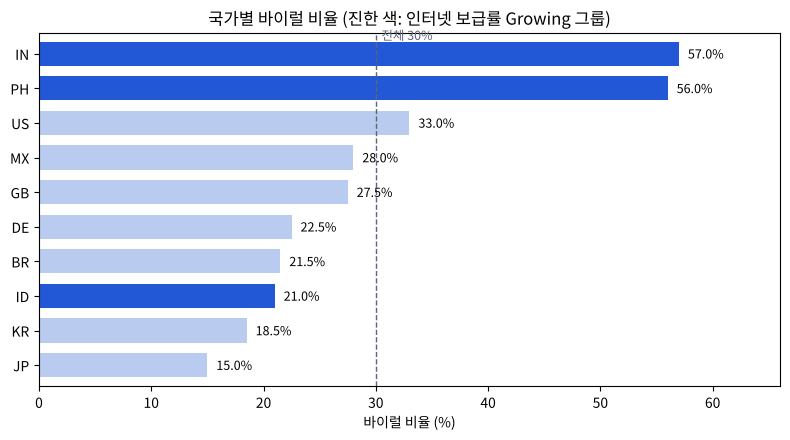

In [6]:
rate = df.groupby("region")["is_viral"].mean().mul(100).sort_values()
colors = ["#2257D6" if r in ("IN", "PH", "ID") else "#B9CBEF" for r in rate.index]
ax = rate.plot(kind="barh", figsize=(8, 4.5), color=colors, width=0.7)
ax.axvline(30, color="#5B6577", linestyle="--", linewidth=1)
ax.text(30.5, len(rate) - 0.6, "전체 30%", color="#5B6577", fontsize=9); ax.set_xlim(0, 66)
for i, v in enumerate(rate.values):
    ax.text(v + 0.8, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlabel("바이럴 비율 (%)"); ax.set_ylabel(""); ax.set_title("국가별 바이럴 비율 (진한 색: 인터넷 보급률 Growing 그룹)")
plt.tight_layout(); plt.savefig("../images/viral_rate_by_country.png", dpi=150); plt.show()

## 5. 모델 비교

- 8:2 Stratified Split
- 클래스 불균형(30:70)은 각 모델의 가중치로 보정 (XGBoost `scale_pos_weight` = 일반/바이럴 ≈ 2.33)

In [7]:
features = ["categoryId", "region_encoded", "dev_group_encoded", "culture_encoded", "internet_encoded",
            "has_hashtag", "hashtag_count", "hour", "day_of_week", "is_weekend", "title_length"]
X, y = df[features], df["is_viral"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

def make_xgb():
    return XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=42,
                         eval_metric="logloss", scale_pos_weight=scale_weight)

models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, class_weight="balanced"),
    "XGBoost": make_xgb(),
}
rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    rows.append({"모델": name, "정확도(%)": round(accuracy_score(y_test, pred) * 100, 1),
                 "바이럴 Recall(%)": round(recall_score(y_test, pred) * 100, 1)})
result = pd.DataFrame(rows).set_index("모델")
result.loc["기준선(전부 일반으로 예측)"] = [round((1 - y_test.mean()) * 100, 1), 0.0]
result

,정확도(%),바이럴 Recall(%)
모델,,
Logistic Regression,64.2,58.3
Random Forest,77.0,64.2
XGBoost,80.0,70.0
기준선(전부 일반으로 예측),70.0,0.0


In [8]:
best = models["XGBoost"]
pred = best.predict(X_test)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=["일반", "바이럴"]))

[[236  44]
 [ 36  84]]
              precision    recall  f1-score   support

          일반       0.87      0.84      0.86       280
         바이럴       0.66      0.70      0.68       120

    accuracy                           0.80       400
   macro avg       0.76      0.77      0.77       400
weighted avg       0.80      0.80      0.80       400



In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(make_xgb(), X, y, cv=cv)
print(f"5-Fold Stratified CV 평균 정확도: {scores.mean():.3f}  {scores.round(3)}")

5-Fold Stratified CV 평균 정확도: 0.773  [0.772 0.802 0.775 0.768 0.748]


## 6. 변수 중요도

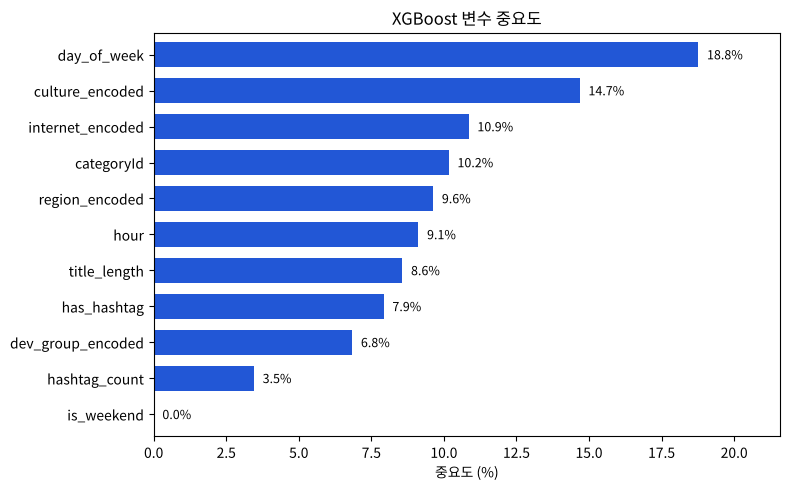

In [10]:
imp = pd.Series(best.feature_importances_, index=features).sort_values()
ax = (imp * 100).plot(kind="barh", figsize=(8, 5), color="#2257D6", width=0.7)
for i, v in enumerate(imp.values * 100):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, imp.max() * 100 * 1.15); ax.set_xlabel("중요도 (%)"); ax.set_title("XGBoost 변수 중요도")
plt.tight_layout(); plt.savefig("../images/feature_importance.png", dpi=150); plt.show()

## 7. 결과 검증과 한계

모델 성능을 그대로 받아들이기 전에 세 가지를 추가로 확인

### 7-1. 업로드 요일이 1위인 이유

수집 직전 하루에 업로드된 영상이 대부분이라, 요일 변수가 사실상 **업로드 후 경과 시간**을 반영할 가능성 확인

In [11]:
print(df["publishedAt"].dt.date.value_counts().sort_index().tail(5))
age_h = (df["publishedAt"].max() - df["publishedAt"]).dt.total_seconds() / 3600
age_bin = pd.cut(age_h, [-1, 12, 24, 48, 96, np.inf], labels=["12시간 이내", "12~24시간", "1~2일", "2~4일", "4일 이상"])
df.groupby(age_bin, observed=True)["is_viral"].agg(["mean", "size"]).rename(columns={"mean": "바이럴 비율", "size": "영상 수"}).round(2)

publishedAt
2025-11-14      55
2025-11-15     142
2025-11-16     277
2025-11-17    1283
2025-11-18      76
Name: count, dtype: int64


,바이럴 비율,영상 수
publishedAt,,
12시간 이내,0.20,659
12~24시간,0.24,638
1~2일,0.43,309
2~4일,0.50,221
4일 이상,0.40,173


→ 업로드 후 12시간 이내 영상의 바이럴 비율 20%, 2~4일 지난 영상은 50%
→ 요일 효과의 상당 부분이 '조회수가 쌓일 시간'의 차이일 수 있음. 여러 날에 걸쳐 수집하거나 경과 시간을 통제한 비교가 필요

### 7-2. 해시태그 변수

`hashtags` 열은 API의 `tags`(영상 태그)로, `#` 기호가 거의 없어 `hashtag_count`가 대부분 0

In [12]:
print("hashtag_count = 0 비율:", round((df["hashtag_count"] == 0).mean() * 100, 1), "%")
print("tags가 있는 영상 비율:", round(df["has_hashtag"].mean() * 100, 1), "%")

hashtag_count = 0 비율: 97.6 %
tags가 있는 영상 비율: 79.0 %


### 7-3. 처음 보는 국가에도 통하는가

국가 하나를 통째로 빼고 학습한 뒤 그 국가를 예측 (Leave-One-Country-Out)

In [13]:
loco = cross_val_score(make_xgb(), X, y, groups=df["region"], cv=LeaveOneGroupOut())
print(f"국가 단위 교차검증 평균 정확도: {loco.mean():.3f}")
pd.Series(loco, index=sorted(df["region"].unique())).round(3)

국가 단위 교차검증 평균 정확도: 0.666


BR    0.815
DE    0.805
GB    0.875
ID    0.320
IN    0.555
JP    0.795
KR    0.675
MX    0.675
PH    0.655
US    0.485
dtype: float64

## 정리

- XGBoost가 정확도 80.0%, 바이럴 Recall 70.0%로 가장 좋았고 5-Fold 교차검증 평균 77.3%
- 인터넷 보급률 Growing 그룹(인도·필리핀·인도네시아)의 바이럴 비율이 High 그룹의 약 2배
- 다만 요일 변수는 경과 시간 효과가 섞여 있고, 처음 보는 국가에는 정확도가 크게 낮아짐
- 개선 방향: 여러 날에 걸친 반복 수집, 업로드 후 경과 시간 통제, 국가별 정규화된 바이럴 기준